
# OnTarget — Soccer Goal Probability Prediction Using Deep Learning

**Course:** ARTE4110U — Deep Learning Architectures and Algorithms

**Project:** Final Project — OnTarget

**Group Number:** [Insert Group Number]

**Team Members:**
- Gitae Yang — 100794460
- Arno Nazarian — 100868853
- Nievethan Thanienayagam — 100750591

**Dataset:** StatsBomb Open Data

**Frameworks:** PyTorch and Scikit-learn

**GitHub Repository:** https://github.com/Nievethan/OnTarget

---

## Project Overview

The goal of OnTarget is to predict the probability that a soccer shot will result in a goal using machine learning and deep learning.

The model considers information available when a shot is taken, such as the distance to the goal, shooting angle, body part, shot technique, defensive pressure, and goalkeeper positioning.

This project compares two models:

1. **Logistic Regression:** A baseline model used for comparison.
2. **Multilayer Perceptron (MLP):** A PyTorch neural network with two hidden layers containing 64 and 32 neurons.

Both models will be evaluated using Log Loss, Brier Score, and ROC-AUC.



# 1. Environment Setup

## 1.1 Import Required Libraries

In this section, we import the Python libraries needed to build, train, and evaluate our models.

- **Pandas and NumPy:** Used to load, inspect, and work with the dataset.
- **Matplotlib and Seaborn:** Used to create graphs and visualize results.
- **Scikit-learn:** Used for data splitting, standardization, logistic regression, and evaluation.
- **PyTorch:** Used to build and train the MLP neural network.

We also set a random seed to make our experimental results more reproducible.


In [1]:

# ============================================================
# 1.1 Import Required Libraries
# ============================================================

# Pandas is used to load and manage data tables.
import pandas as pd

# NumPy is used for numerical calculations.
import numpy as np

# Matplotlib and Seaborn are used to create graphs.
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn tools for splitting and preparing the data.
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

# Logistic regression will be our baseline model.
from sklearn.linear_model import LogisticRegression

# Tools for evaluating model performance.
from sklearn.metrics import (
    log_loss,
    brier_score_loss,
    roc_auc_score
)

# PyTorch is used to build and train the neural network.
import torch
import torch.nn as nn
import torch.optim as optim

# DataLoader helps us train the model in smaller batches.
from torch.utils.data import TensorDataset, DataLoader

# Used to make random operations reproducible.
import random

# Set the same random seed across all libraries.
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use a GPU if one is available.
# Otherwise, the model will run on the CPU.
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("Device:", device)


Libraries imported successfully!
PyTorch version: 2.14.1+cu130
Device: cuda



# 2. Load and Validate the Dataset

## 2.1 Upload the Cleaned Dataset

We use the cleaned dataset prepared during the data preprocessing stage.

The dataset is stored in Parquet format, which provides efficient storage for large tables.

We upload the file to Google Colab and load it into a Pandas DataFrame.

This allows us to inspect its contents before preparing the data for model training.


In [2]:

# ============================================================
# 2.1 Upload and Load the Cleaned Dataset
# ============================================================

# Import the Colab file upload tool.
from google.colab import files

# Upload the cleaned Parquet dataset from our computer.
uploaded = files.upload()

# Specify the name of our cleaned dataset.
file_name = "ontarget_shots_cleaned.parquet"

# Make sure the expected file was uploaded.
if file_name not in uploaded:
    raise FileNotFoundError(
        f"Please upload the file named {file_name}"
    )

# Load the Parquet file into a Pandas DataFrame.
df = pd.read_parquet(file_name)

# Confirm that the dataset loaded successfully.
print("Dataset loaded successfully!")

# Display the number of rows and columns.
print("Dataset shape:", df.shape)

# Display the first five rows of the dataset.
display(df.head())


Saving ontarget_shots_cleaned.parquet to ontarget_shots_cleaned.parquet
Dataset loaded successfully!
Dataset shape: (106717, 54)


,shot_id,match_id,period,minute,second,team_name,player_name,x,y,end_x,...,play_pattern_From Goal Kick,play_pattern_From Keeper,play_pattern_From Kick Off,play_pattern_From Throw In,play_pattern_Other,play_pattern_Regular Play,shot_type_Corner,shot_type_Free Kick,shot_type_Kick Off,shot_type_Open Play
0,becd7956-ce44-479e-8fc9-16a2d1f1f349,15946,1,2,29,Barcelona,Lionel Andrés Messi Cuccittini,111.5,52.9,120.0,...,0,0,0,1,0,0,0,0,0,1
1,9107d374-2942-4876-a14f-1b9f86901c15,15946,1,5,39,Barcelona,Jordi Alba Ramos,113.9,26.4,120.0,...,0,0,0,0,0,1,0,0,0,1
2,ddd194ca-08fb-43d0-87c2-33647f975f9f,15946,1,15,29,Barcelona,Lionel Andrés Messi Cuccittini,93.7,34.7,117.5,...,0,1,0,0,0,0,0,0,0,1
3,86596ddb-d824-4e5e-b18c-b4442e9ce7cf,15946,1,16,20,Deportivo Alavés,Rubén Sobrino Pozuelo,109.2,39.1,120.0,...,0,0,0,0,0,1,0,0,0,1
4,3ed2b107-be17-42d5-9d1b-25006a0e55cb,15946,1,18,16,Barcelona,Luis Alberto Suárez Díaz,107.8,24.7,120.0,...,0,0,0,0,0,0,0,0,0,1



## 2.2 Validate the Cleaned Dataset

Before training our models, we check that the dataset was processed correctly.

We examine:

1. The total number of shots and columns.
2. Missing values in the dataset.
3. The number of goals and non-goals.
4. The distribution of the target variable.
5. Whether the goal labels contain only 0 and 1.
6. Duplicate shot identifiers.

These checks help us identify possible problems before building the models.


In [3]:

# ============================================================
# 2.2 Validate the Cleaned Dataset
# ============================================================

# Display the number of rows and columns.
print("Total shots:", len(df))
print("Total columns:", len(df.columns))

# Check whether the required columns exist.
required_columns = ["shot_id", "match_id", "is_goal"]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

# Count missing values across all columns.
missing_values = df.isnull().sum()

print("\nTotal missing values:", missing_values.sum())

# Show columns that contain missing values.
print("\nColumns with missing values:")
print(missing_values[missing_values > 0])

# Count duplicate shot identifiers.
duplicate_shots = df["shot_id"].duplicated().sum()

print("\nDuplicate shot IDs:", duplicate_shots)

# Count the number of goals and non-goals.
goal_counts = df["is_goal"].value_counts().sort_index()

print("\nGoal label distribution:")
print(goal_counts)

# Calculate the percentage of shots resulting in goals.
goal_rate = df["is_goal"].mean() * 100

print(f"\nGoal conversion rate: {goal_rate:.2f}%")

# Confirm that the target contains only binary values.
valid_labels = df["is_goal"].dropna().isin([0, 1]).all()

if not valid_labels or df["is_goal"].isnull().any():
    raise ValueError(
        "The target column must contain only 0 and 1."
    )

print("\nGoal labels are valid (0 or 1).")
print("Initial dataset validation completed!")


Total shots: 106717
Total columns: 54

Total missing values: 32769

Columns with missing values:
end_z    32769
dtype: int64

Duplicate shot IDs: 0

Goal label distribution:
is_goal
0    95792
1    10925
Name: count, dtype: int64

Goal conversion rate: 10.24%

Goal labels are valid (0 or 1).
Initial dataset validation completed!



# 3. Feature Selection and Data Splitting

## 3.1 Select Input Features and Target Variable

In this section, we separate the information used to predict goals from the actual goal outcomes.

The input features include shot distance, shooting angle, shot type, defensive pressure, goalkeeper positioning, and other information available when the shot is taken.

The target variable is `is_goal`, where:
- **0:** The shot did not result in a goal.
- **1:** The shot resulted in a goal.

We remove metadata and outcome-related columns that should not be used for prediction. This prevents data leakage, where the model could learn from information that would only be known after the shot.

We also remove constant features because they do not provide useful information for distinguishing different shots.


### Feature Refinement

After reviewing the preprocessed dataset, we removed several features that were unnecessary, redundant, or potentially affected by data leakage.

The match time features (`period`, `minute`, and `second`) were excluded because our initial model focuses on shot conditions rather than match timing. We also removed `shot_angle_deg` because the angle is already represented in radians.

The `deflected` feature was excluded because it may describe information that becomes available after the shot is taken.

This leaves 37 input features for our initial model, including shot geometry, shooting context, defensive positioning, and categorical shot information.


In [5]:

# ============================================================
# 3.1 Select Input Features and Target Variable
# ============================================================

# These columns contain metadata, shot outcomes, or
# information that should not be used as model inputs.
excluded_columns = [
    "shot_id",
    "match_id",
    "team_name",
    "player_name",
    "end_x",
    "end_y",
    "end_z",
    "outcome_raw",
    "statsbomb_xg",
    "is_on_target",
    "is_goal"
]

# These features are not needed for our initial model.
# Match time is not central to our shot-quality analysis.
# Shot angle in degrees duplicates the radians feature.
# Deflected may reveal information after the shot.
additional_exclusions = [
    "period",
    "minute",
    "second",
    "shot_angle_deg",
    "deflected"
]

# Combine both exclusion lists.
all_excluded_columns = (
    excluded_columns + additional_exclusions
)

# Select the columns that are not excluded.
feature_columns = [
    col for col in df.columns
    if col not in all_excluded_columns
]

# Find features that always have the same value.
# A constant feature cannot help distinguish shots.
constant_columns = [
    col for col in feature_columns
    if df[col].nunique(dropna=False) <= 1
]

# Remove constant features from the model inputs.
feature_columns = [
    col for col in feature_columns
    if col not in constant_columns
]

# X contains the input features for our models.
X = df[feature_columns].copy()

# y contains the actual goal outcomes.
# 0 means no goal, and 1 means goal.
y = df["is_goal"].astype(int).copy()

# Display the final feature information.
print("Original dataset columns:", len(df.columns))
print("Selected input features:", len(feature_columns))
print("Target variable: is_goal")

print("\nRemoved constant features:")
print(constant_columns)

print("\nFinal input features:")
for i, col in enumerate(feature_columns, start=1):
    print(f"{i}. {col}")

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)


Original dataset columns: 54
Selected input features: 37
Target variable: is_goal

Removed constant features:
['has_freeze_frame']

Final input features:
1. x
2. y
3. distance_to_goal
4. shot_angle_rad
5. under_pressure
6. first_time
7. one_on_one
8. aerial_won
9. open_goal
10. defenders_in_cone
11. gk_in_cone
12. closest_defender_dist
13. gk_distance_to_goal
14. body_part_Head
15. body_part_Left Foot
16. body_part_Other
17. body_part_Right Foot
18. technique_Backheel
19. technique_Diving Header
20. technique_Half Volley
21. technique_Lob
22. technique_Normal
23. technique_Overhead Kick
24. technique_Volley
25. play_pattern_From Corner
26. play_pattern_From Counter
27. play_pattern_From Free Kick
28. play_pattern_From Goal Kick
29. play_pattern_From Keeper
30. play_pattern_From Kick Off
31. play_pattern_From Throw In
32. play_pattern_Other
33. play_pattern_Regular Play
34. shot_type_Corner
35. shot_type_Free Kick
36. shot_type_Kick Off
37. shot_type_Open Play

Input shape: (106717, 37)


## 3.2 Validate the Selected Features

Before splitting the dataset, we verify that the selected input features are suitable for machine learning.

We check that:

1. All input features contain numerical values.
2. No selected features contain missing values.
3. No selected features contain infinite values.
4. The target variable contains valid goal labels.

These checks ensure that the input data can be used by both the logistic regression baseline and the PyTorch MLP.

The original dataset contains missing values in `end_z`, but this column is excluded because it describes where the shot ended.


In [6]:

# ============================================================
# 3.2 Validate the Selected Features
# ============================================================

# Check whether all input columns are numerical.
non_numeric_columns = X.select_dtypes(
    exclude=["number", "bool"]
).columns.tolist()

print("Non-numeric columns:", non_numeric_columns)

# Count missing values in the selected features.
total_missing = X.isnull().sum().sum()

print("Missing values in input features:", total_missing)

# Convert the selected features into a NumPy array.
# We use float64 here to check the numerical values.
# The PyTorch conversion to float32 will happen later.
if len(non_numeric_columns) == 0:
    X_values = X.to_numpy(dtype=np.float64)

    # Check for infinity or other non-finite values.
    total_invalid = (~np.isfinite(X_values)).sum()

    print("Non-finite values:", total_invalid)

else:
    total_invalid = None
    print("Cannot check numerical values until all features are numeric.")

# Check that the target contains only 0 and 1.
valid_target = y.isin([0, 1]).all()

print("Target contains only 0 and 1:", valid_target)

# Stop execution if any validation check fails.
if non_numeric_columns:
    raise ValueError("Some selected features are not numerical.")

if total_missing > 0:
    raise ValueError("Missing values found in selected features.")

if total_invalid > 0:
    raise ValueError("Invalid numerical values found in selected features.")

if not valid_target:
    raise ValueError("Invalid target values found.")

print("\nAll selected features passed validation!")


Non-numeric columns: []
Missing values in input features: 0
Non-finite values: 0
Target contains only 0 and 1: True

All selected features passed validation!



## 3.3 Split the Dataset into Training, Validation, and Testing Sets

We divide the dataset into three separate sets, following the 70/15/15 split proposed in our project proposal.

- **Training set (70%):** Used to teach the models how shot conditions relate to scoring goals.
- **Validation set (15%):** Used to monitor model performance during development and help select training settings.
- **Testing set (15%):** Used for the final evaluation on data the models have not seen during training or model selection.

We use a group-based split using `match_id`. This keeps all shots from the same soccer match in the same dataset split.

Grouping by match reduces the chance that the models learn match-specific information that could make the evaluation results misleading.

We use random seed 42 to make the split reproducible. The exact percentages may differ slightly because complete matches are kept together.


In [7]:

# ============================================================
# 3.3 Split the Dataset into Training, Validation, and Test Sets
# ============================================================

# Use match IDs to keep shots from the same match together.
groups = df["match_id"]

# Create the first group-based split.
# Approximately 70% of matches will be used for training.
# The remaining 30% will be held out.
first_split = GroupShuffleSplit(
    n_splits=1,
    train_size=0.70,
    random_state=SEED
)

# Get row positions for the training and remaining data.
train_idx, remaining_idx = next(
    first_split.split(X, y, groups=groups)
)

# Create the training dataset.
X_train = X.iloc[train_idx].copy()
y_train = y.iloc[train_idx].copy()

# Create the remaining dataset for validation and testing.
X_remaining = X.iloc[remaining_idx].copy()
y_remaining = y.iloc[remaining_idx].copy()

# Get the match IDs belonging to the remaining dataset.
remaining_groups = groups.iloc[remaining_idx]

# Split the remaining matches equally.
# This gives approximately 15% validation and 15% testing.
second_split = GroupShuffleSplit(
    n_splits=1,
    train_size=0.50,
    random_state=SEED
)

# These positions are relative to the remaining dataset.
val_idx, test_idx = next(
    second_split.split(
        X_remaining,
        y_remaining,
        groups=remaining_groups
    )
)

# Create the validation dataset.
X_val = X_remaining.iloc[val_idx].copy()
y_val = y_remaining.iloc[val_idx].copy()

# Create the testing dataset.
X_test = X_remaining.iloc[test_idx].copy()
y_test = y_remaining.iloc[test_idx].copy()

# Display the number of shots in each dataset.
print("Data splitting completed!")

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nTotal samples:",
      len(X_train) + len(X_val) + len(X_test))


Data splitting completed!

Training samples: 74597
Validation samples: 15850
Testing samples: 16270

Total samples: 106717



## 3.4 Verify the Data Split and Class Distribution

After splitting the dataset, we check whether the training, validation, and testing sets were created correctly.

We verify that:

1. All original shots are included in exactly one split.
2. No soccer match appears in more than one split.
3. The three sets have approximately the intended 70/15/15 proportions.
4. Each set contains both goals and non-goals.
5. The goal conversion rates are reasonably similar across the three sets.

Because goals occur less frequently than missed shots, checking the class distribution helps us understand whether each set is suitable for training and evaluation.


In [8]:

# ============================================================
# 3.4 Verify the Data Split and Class Distribution
# ============================================================

# Calculate the total number of shots.
total_shots = len(df)

# Store the names and target labels for each dataset.
datasets = {
    "Training": y_train,
    "Validation": y_val,
    "Testing": y_test
}

# Display the size and goal distribution of each dataset.
print("DATASET SPLIT SUMMARY")
print("-" * 65)

for name, labels in datasets.items():

    # Calculate the percentage of all shots in this split.
    percentage = (len(labels) / total_shots) * 100

    # Count goals and missed shots.
    goals = (labels == 1).sum()
    non_goals = (labels == 0).sum()

    # Calculate the goal conversion rate.
    goal_rate = labels.mean() * 100

    print(f"\n{name} Set")
    print(f"Samples: {len(labels):,}")
    print(f"Dataset Percentage: {percentage:.2f}%")
    print(f"Goals: {goals:,}")
    print(f"Non-goals: {non_goals:,}")
    print(f"Goal Rate: {goal_rate:.2f}%")

# Collect the match IDs found in each split.
train_matches = set(df.iloc[train_idx]["match_id"])

val_matches = set(
    df.iloc[remaining_idx]
      .iloc[val_idx]["match_id"]
)

test_matches = set(
    df.iloc[remaining_idx]
      .iloc[test_idx]["match_id"]
)

# Check whether any match appears in multiple datasets.
train_val_overlap = train_matches & val_matches
train_test_overlap = train_matches & test_matches
val_test_overlap = val_matches & test_matches

# Check that the total number of shots was preserved.
all_samples_preserved = (
    len(X_train) + len(X_val) + len(X_test)
    == len(df)
)

# Check that all matches belong to only one split.
no_match_overlap = (
    len(train_val_overlap) == 0
    and len(train_test_overlap) == 0
    and len(val_test_overlap) == 0
)

print("\n" + "-" * 65)
print("SPLIT VERIFICATION")
print("-" * 65)

print("All samples preserved:", all_samples_preserved)
print("No match overlap:", no_match_overlap)

print("Training matches:", len(train_matches))
print("Validation matches:", len(val_matches))
print("Testing matches:", len(test_matches))

# Make sure the split is valid before continuing.
if not all_samples_preserved:
    raise ValueError("Some samples were lost during splitting.")

if not no_match_overlap:
    raise ValueError("Some matches appear in multiple splits.")

# Both classes must exist in every split.
for name, labels in datasets.items():
    if labels.nunique() != 2:
        raise ValueError(
            f"{name} set does not contain both classes."
        )

print("\nData splitting verification passed!")


DATASET SPLIT SUMMARY
-----------------------------------------------------------------

Training Set
Samples: 74,597
Dataset Percentage: 69.90%
Goals: 7,623
Non-goals: 66,974
Goal Rate: 10.22%

Validation Set
Samples: 15,850
Dataset Percentage: 14.85%
Goals: 1,609
Non-goals: 14,241
Goal Rate: 10.15%

Testing Set
Samples: 16,270
Dataset Percentage: 15.25%
Goals: 1,693
Non-goals: 14,577
Goal Rate: 10.41%

-----------------------------------------------------------------
SPLIT VERIFICATION
-----------------------------------------------------------------
All samples preserved: True
No match overlap: True
Training matches: 2964
Validation matches: 635
Testing matches: 636

Data splitting verification passed!



# 4. Data Standardization

## 4.1 Identify Numerical and Categorical Features

Before training our models, we prepare the selected input features so they can be processed efficiently.

Our dataset contains two types of features:

- **Numerical features:** Values such as shot distance, shooting angle, number of defenders, and goalkeeper distance.
- **Binary features:** Values represented by 0 or 1, such as whether a shot was taken under pressure, or whether a particular shooting technique was used.

Numerical features can have very different ranges. For example, shot distance may be much larger than the shooting angle in radians.

We use standardization to place numerical features on a comparable scale.

Binary features are kept as 0 and 1 because they already represent simple yes/no conditions or one-hot encoded categories.


In [9]:

# ============================================================
# 4.1 Identify Numerical and Binary Features
# ============================================================

# Create empty lists for the two types of features.
numerical_features = []
binary_features = []

# Go through every selected input feature.
for col in X_train.columns:

    # Get the unique values found in this feature.
    unique_values = X_train[col].dropna().unique()

    # Check whether the feature contains only 0 and 1.
    # These are binary features and do not need scaling.
    if set(unique_values).issubset({0, 1}):
        binary_features.append(col)

    # Features with other numerical values will be scaled.
    else:
        numerical_features.append(col)

# Display the results.
print("Total selected features:", X_train.shape[1])

print("\nNumerical features:", len(numerical_features))
for col in numerical_features:
    print("-", col)

print("\nBinary features:", len(binary_features))
for col in binary_features:
    print("-", col)

# Make sure every input feature belongs to one group.
assert (
    len(numerical_features) + len(binary_features)
    == X_train.shape[1]
), "Some features were not categorized correctly."

print("\nFeature type identification completed!")


Total selected features: 37

Numerical features: 7
- x
- y
- distance_to_goal
- shot_angle_rad
- defenders_in_cone
- closest_defender_dist
- gk_distance_to_goal

Binary features: 30
- under_pressure
- first_time
- one_on_one
- aerial_won
- open_goal
- gk_in_cone
- body_part_Head
- body_part_Left Foot
- body_part_Other
- body_part_Right Foot
- technique_Backheel
- technique_Diving Header
- technique_Half Volley
- technique_Lob
- technique_Normal
- technique_Overhead Kick
- technique_Volley
- play_pattern_From Corner
- play_pattern_From Counter
- play_pattern_From Free Kick
- play_pattern_From Goal Kick
- play_pattern_From Keeper
- play_pattern_From Kick Off
- play_pattern_From Throw In
- play_pattern_Other
- play_pattern_Regular Play
- shot_type_Corner
- shot_type_Free Kick
- shot_type_Kick Off
- shot_type_Open Play

Feature type identification completed!



## 4.2 Standardize Numerical Features

We use Scikit-learn's `StandardScaler` to standardize numerical input features.

Standardization subtracts the mean and divides by the standard deviation of a feature.

This helps the logistic regression baseline and PyTorch MLP train more efficiently because the numerical features have comparable scales.

To prevent data leakage, the scaler is fitted using only the training dataset.

The same fitted scaler is then applied to the validation and testing datasets.

We do not use validation or testing data to calculate the scaling values.

Binary features remain unchanged as 0 or 1.


In [10]:

# ============================================================
# 4.2 Standardize Numerical Features
# ============================================================

# Create copies of the datasets.
# This preserves the original train, validation, and test data.
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

# Create a StandardScaler for the numerical features.
scaler = StandardScaler()

# Learn the mean and standard deviation from training data.
# Then use those values to standardize the training features.
X_train_scaled[numerical_features] = scaler.fit_transform(
    X_train[numerical_features]
)

# Use the same training-set scaling values for validation.
# We use transform(), not fit_transform().
X_val_scaled[numerical_features] = scaler.transform(
    X_val[numerical_features]
)

# Apply the same scaling values to the testing dataset.
# The test data does not influence the scaler.
X_test_scaled[numerical_features] = scaler.transform(
    X_test[numerical_features]
)

# Convert all feature values to float32.
# This is compatible with PyTorch and uses less memory.
X_train_scaled = X_train_scaled.astype(np.float32)
X_val_scaled = X_val_scaled.astype(np.float32)
X_test_scaled = X_test_scaled.astype(np.float32)

# Display the resulting dataset shapes.
print("Data standardization completed!")

print("\nTraining shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nNumerical features standardized:", len(numerical_features))
print("Binary features kept unchanged:", len(binary_features))


Data standardization completed!

Training shape: (74597, 37)
Validation shape: (15850, 37)
Testing shape: (16270, 37)

Numerical features standardized: 7
Binary features kept unchanged: 30



## 4.3 Verify Standardized Features

After applying standardization, we verify that the prepared datasets are correct.

We check that:

1. The training, validation, and testing datasets retain their original sizes.
2. The standardized numerical training features have means close to 0.
3. Numerical training features have standard deviations close to 1.
4. Binary features still contain only 0 and 1.
5. No missing or infinite values were introduced.

These checks help confirm that the datasets are ready for model training.


In [14]:

# ============================================================
# 4.3 Verify Standardized Features
# ============================================================

# Check that dataset sizes remain unchanged.
assert X_train_scaled.shape == X_train.shape
assert X_val_scaled.shape == X_val.shape
assert X_test_scaled.shape == X_test.shape

print("Dataset shapes are preserved.")

# Check the numerical feature statistics.
if numerical_features:

    # Calculate the mean of each numerical feature.
    train_means = X_train_scaled[numerical_features].mean()

    # Calculate standard deviations using ddof=0.
    train_stds = X_train_scaled[numerical_features].std(
        ddof=0
    )

    # Create a table to inspect the results.
    scaling_summary = pd.DataFrame({
        "Mean": train_means,
        "Standard Deviation": train_stds
    })

    print("\nTraining numerical feature statistics:")
    display(scaling_summary.round(4))

    # A small difference is acceptable due to
    # floating-point precision.
    tolerance = 1e-3

    # Check that means are approximately zero.
    assert np.allclose(
        train_means.to_numpy(),
        0,
        atol=tolerance
    ), "Some feature means are not close to zero."

    # Identify features with non-zero variance.
    non_constant = scaler.var_ > 0

    # Check that standard deviations are approximately one.
    assert np.allclose(
        train_stds.to_numpy()[non_constant],
        1,
        atol=tolerance
    ), "Some feature standard deviations are not close to one."

    print("\nNumerical standardization verified!")

# Check that binary features still contain 0 and 1.
for col in binary_features:

    assert X_train_scaled[col].isin([0, 1]).all()
    assert X_val_scaled[col].isin([0, 1]).all()
    assert X_test_scaled[col].isin([0, 1]).all()

print("Binary features remain unchanged.")

# Check all datasets for invalid numerical values.
datasets_scaled = {
    "Training": X_train_scaled,
    "Validation": X_val_scaled,
    "Testing": X_test_scaled
}

for name, dataset in datasets_scaled.items():

    # Convert the dataset into a NumPy array.
    values = dataset.to_numpy()

    # Make sure there are no missing or infinite values.
    assert np.isfinite(values).all(), (
        f"{name} dataset contains invalid values."
    )

    print(f"{name} dataset contains valid numerical values.")

# Make sure the input and target sizes match.
assert len(X_train_scaled) == len(y_train)
assert len(X_val_scaled) == len(y_val)
assert len(X_test_scaled) == len(y_test)

print("\nAll standardization checks passed!")
print("Datasets are ready for model training.")


Dataset shapes are preserved.

Training numerical feature statistics:


,Mean,Standard Deviation
x,0.0,1.0000
y,-0.0,1.0000
distance_to_goal,-0.0,1.0000
shot_angle_rad,0.0,1.0000
defenders_in_cone,0.0,1.0002
closest_defender_dist,0.0,1.0000
gk_distance_to_goal,-0.0,1.0000



Numerical standardization verified!
Binary features remain unchanged.
Training dataset contains valid numerical values.
Validation dataset contains valid numerical values.
Testing dataset contains valid numerical values.

All standardization checks passed!
Datasets are ready for model training.



# 5. Logistic Regression Baseline

## 5.1 Initialize the Logistic Regression Model

Logistic regression is used as the baseline model for the OnTarget project.

It is a supervised learning algorithm used for binary classification. In our project, it predicts the probability that a soccer shot will result in a goal.

The model learns how input features, such as shot distance, shooting angle, defensive pressure, and goalkeeper positioning, relate to the likelihood of scoring.

Unlike a neural network, logistic regression does not contain hidden layers. It learns a linear combination of the input features and uses a sigmoid function to produce a probability between 0 and 1.

We use Scikit-learn's `LogisticRegression` implementation with a fixed random seed for reproducibility.

The trained baseline will later be compared against our PyTorch MLP.


In [15]:

# ============================================================
# 5.1 Initialize the Logistic Regression Baseline
# ============================================================

# Create the logistic regression model.
# This model will learn the relationship between
# shot features and the probability of scoring.
logistic_model = LogisticRegression(

    # Use the LBFGS optimization algorithm.
    # It works well for logistic regression on datasets
    # with a moderate number of input features.
    solver="lbfgs",

    # Allow up to 1000 optimization iterations.
    # This helps the model reach convergence.
    max_iter=1000,

    # Use a fixed random seed for reproducibility.
    random_state=SEED
)

# Display the model settings.
print("Logistic regression model initialized!")
print("\nModel configuration:")
print(logistic_model)



Logistic regression model initialized!

Model configuration:
LogisticRegression(max_iter=1000, random_state=42)



## 5.2 Train the Logistic Regression Model

In this section, we train the logistic regression baseline using the standardized training dataset.

The model receives:

- `X_train_scaled`: The 37 selected and prepared input features.
- `y_train`: The actual shot outcomes, represented by 0 for no goal and 1 for goal.

During training, logistic regression learns feature weights that help estimate the probability of scoring.

Only the training dataset is used to fit the model. The validation and testing datasets are not used to learn the model weights.

After training, we check whether the optimization process successfully converged.


In [16]:

# ============================================================
# 5.2 Train the Logistic Regression Baseline
# ============================================================

# Import time to measure how long training takes.
import time

# Record the starting time.
start_time = time.perf_counter()

# Train the logistic regression model.
# X_train_scaled contains the input features.
# y_train contains the actual goal labels.
logistic_model.fit(
    X_train_scaled,
    y_train
)

# Record the ending time.
end_time = time.perf_counter()

# Calculate the total training time in seconds.
logistic_training_time = end_time - start_time

# Display the training results.
print("Logistic regression training completed!")

print(
    f"\nTraining time: {logistic_training_time:.2f} seconds"
)

# Display how many iterations were used.
# The optimization process stops when it converges
# or when it reaches the maximum allowed iterations.
print(
    "Optimization iterations:",
    logistic_model.n_iter_[0]
)

# Display the number of learned input weights.
print(
    "Number of feature weights:",
    logistic_model.coef_.shape[1]
)

# Display the intercept learned by the model.
print(
    "Model intercept:",
    logistic_model.intercept_[0]
)

# Warn if the model reached the iteration limit.
if logistic_model.n_iter_[0] >= logistic_model.max_iter:
    print(
        "\nWarning: The model reached the maximum "
        "number of iterations."
    )
else:
    print("\nTraining stopped before the iteration limit.")


Logistic regression training completed!

Training time: 1.03 seconds
Optimization iterations: 50
Number of feature weights: 37
Model intercept: -1.0752042537625326

Training stopped before the iteration limit.



## 5.3 Generate Training and Validation Predictions

After training the baseline model, we generate predictions for the training and validation datasets.

Instead of predicting only whether a shot is a goal or a miss, we calculate the probability of scoring.

For example:

- A predicted probability of 0.05 means a 5% estimated chance of scoring.
- A predicted probability of 0.25 means a 25% estimated chance of scoring.
- A predicted probability of 0.80 means an 80% estimated chance of scoring.

We use the `predict_proba()` method to obtain these probabilities.

The training predictions help us understand how the model fits the data it learned from.

The validation predictions provide an initial check of how the model performs on unseen matches.

The testing dataset remains untouched for the final evaluation.


In [17]:

# ============================================================
# 5.3 Generate Training and Validation Predictions
# ============================================================

# Predict the probability of scoring for training shots.
# [:, 1] selects the probability of class 1 (Goal).
logistic_train_probs = logistic_model.predict_proba(
    X_train_scaled
)[:, 1]

# Predict the probability of scoring for validation shots.
# These matches were not used to train the model.
logistic_val_probs = logistic_model.predict_proba(
    X_val_scaled
)[:, 1]

# Display the number of generated predictions.
print("Training predictions:", len(logistic_train_probs))
print("Validation predictions:", len(logistic_val_probs))

# Display the first five validation predictions.
print("\nFirst five validation predictions:")

for i, probability in enumerate(
    logistic_val_probs[:5],
    start=1
):
    print(
        f"Shot {i}: {probability * 100:.2f}% "
        "estimated chance of scoring"
    )

# Check that probabilities are between 0 and 1.
assert np.all(
    (logistic_train_probs >= 0) &
    (logistic_train_probs <= 1)
)

assert np.all(
    (logistic_val_probs >= 0) &
    (logistic_val_probs <= 1)
)

print("\nAll predicted probabilities are valid!")


Training predictions: 74597
Validation predictions: 15850

First five validation predictions:
Shot 1: 90.72% estimated chance of scoring
Shot 2: 6.54% estimated chance of scoring
Shot 3: 4.25% estimated chance of scoring
Shot 4: 12.91% estimated chance of scoring
Shot 5: 0.22% estimated chance of scoring

All predicted probabilities are valid!



## 5.4 Basic Training and Validation Check

We perform a basic performance check to confirm that the logistic regression baseline is producing meaningful probability predictions.

We calculate three metrics:

1. **Log Loss:** Measures how well the predicted probabilities match the actual goal outcomes. Lower values are better.
2. **Brier Score:** Measures the average squared difference between predicted probabilities and actual outcomes. Lower values are better.
3. **ROC-AUC:** Measures how well the model ranks goals above non-goals. Higher values are better, with 0.5 representing random ranking performance.

We calculate these metrics for the training and validation datasets.

The validation results are used only as an initial model-development check. The final test-set evaluation and detailed comparison with the MLP will be completed by the team member responsible for experiments and analysis.


In [18]:

# ============================================================
# 5.4 Basic Training and Validation Performance Check
# ============================================================

# Create a function to calculate our three evaluation metrics.
# This lets us reuse the same calculation for both datasets.
def calculate_baseline_metrics(y_true, y_prob):

    # Log Loss measures the quality of predicted probabilities.
    loss = log_loss(y_true, y_prob)

    # Brier Score measures the squared probability error.
    brier = brier_score_loss(y_true, y_prob)

    # ROC-AUC measures how well goals are ranked
    # above non-goals.
    auc = roc_auc_score(y_true, y_prob)

    # Return all three results.
    return {
        "Log Loss": loss,
        "Brier Score": brier,
        "ROC-AUC": auc
    }


# Calculate metrics for the training dataset.
logistic_train_metrics = calculate_baseline_metrics(
    y_train,
    logistic_train_probs
)

# Calculate metrics for the validation dataset.
logistic_val_metrics = calculate_baseline_metrics(
    y_val,
    logistic_val_probs
)

# Put both results into a comparison table.
logistic_results = pd.DataFrame({
    "Training": logistic_train_metrics,
    "Validation": logistic_val_metrics
}).T

# Display the results with four decimal places.
print("LOGISTIC REGRESSION BASELINE RESULTS")
print("-" * 50)

display(logistic_results.round(4))

# Calculate the difference in Log Loss.
# A large validation increase may indicate overfitting.
log_loss_gap = (
    logistic_val_metrics["Log Loss"]
    - logistic_train_metrics["Log Loss"]
)

print(f"\nValidation - Training Log Loss: {log_loss_gap:.4f}")

print("\nBaseline training and validation check completed!")


LOGISTIC REGRESSION BASELINE RESULTS
--------------------------------------------------


,Log Loss,Brier Score,ROC-AUC
Training,0.267,0.0761,0.8021
Validation,0.265,0.0760,0.8085



Validation - Training Log Loss: -0.0019

Baseline training and validation check completed!



# 6. PyTorch MLP Architecture

## 6.1 Prepare the Data for PyTorch

In this section, we convert our standardized datasets into PyTorch tensors.

PyTorch uses tensors to perform mathematical operations and train neural networks.

We prepare the following datasets:

- **Training features and labels:** Used to train the neural network.
- **Validation features and labels:** Used to monitor performance during training.

The input features and target labels are converted to `float32`, which is commonly used for neural network training.

We also use a DataLoader to divide the training dataset into smaller batches of 64 samples, as specified in our project proposal.

The testing dataset will remain untouched for the final evaluation.


In [19]:

# ============================================================
# 6.1 Prepare the Data for PyTorch
# ============================================================

# Convert the standardized training features into a tensor.
# Each row represents one soccer shot.
X_train_tensor = torch.tensor(
    X_train_scaled.to_numpy(),
    dtype=torch.float32
)

# Convert the training labels into a float32 tensor.
# Reshape the labels to (number of shots, 1).
# This matches the shape of our neural network output.
y_train_tensor = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

# Convert the standardized validation features.
X_val_tensor = torch.tensor(
    X_val_scaled.to_numpy(),
    dtype=torch.float32
)

# Convert the validation labels.
y_val_tensor = torch.tensor(
    y_val.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

# Combine training features and labels into one dataset.
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

# Combine validation features and labels.
val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

# Create a DataLoader for the training dataset.
# Batch size 64 follows our project proposal.
# Shuffle=True changes the shot order between epochs.
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

# Create a DataLoader for the validation dataset.
# Shuffling is not necessary for validation.
val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

# Display the resulting tensor and dataset information.
print("PyTorch datasets created successfully!")

print("\nTraining feature tensor:", X_train_tensor.shape)
print("Training label tensor:", y_train_tensor.shape)

print("\nValidation feature tensor:", X_val_tensor.shape)
print("Validation label tensor:", y_val_tensor.shape)

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))


PyTorch datasets created successfully!

Training feature tensor: torch.Size([74597, 37])
Training label tensor: torch.Size([74597, 1])

Validation feature tensor: torch.Size([15850, 37])
Validation label tensor: torch.Size([15850, 1])

Training batches: 1166
Validation batches: 248



## 6.2 Define the MLP Neural Network

We implement our proposed multilayer perceptron (MLP) using PyTorch.

The neural network contains three fully connected layers:

1. **Input to Hidden Layer 1:** Converts the 37 input features into 64 neurons.
2. **Hidden Layer 1 to Hidden Layer 2:** Converts 64 neurons into 32 neurons.
3. **Hidden Layer 2 to Output:** Converts 32 neurons into one output value.

We use the ReLU activation function after both hidden layers to help the model learn nonlinear relationships between shot conditions and scoring probability.

The output layer returns one raw logit instead of a probability.

We do not apply sigmoid inside the network because `BCEWithLogitsLoss` will handle the sigmoid operation during training.

When generating goal probabilities later, we will apply sigmoid to the output logits.


In [20]:

# ============================================================
# 6.2 Define the OnTarget MLP Neural Network
# ============================================================

# Create our MLP model using PyTorch's nn.Module class.
class OnTargetMLP(nn.Module):

    # Initialize the neural network layers.
    def __init__(self, input_size):

        # Initialize the parent PyTorch class.
        super(OnTargetMLP, self).__init__()

        # First fully connected layer.
        # Converts input features into 64 neurons.
        self.fc1 = nn.Linear(input_size, 64)

        # Second fully connected layer.
        # Converts 64 neurons into 32 neurons.
        self.fc2 = nn.Linear(64, 32)

        # Final output layer.
        # Produces one logit for each soccer shot.
        self.fc3 = nn.Linear(32, 1)

        # ReLU activation helps the model learn
        # nonlinear patterns from the shot features.
        self.relu = nn.ReLU()

    # Define how input data moves through the network.
    def forward(self, x):

        # Pass the input through the first layer and ReLU.
        x = self.relu(self.fc1(x))

        # Pass the result through the second layer and ReLU.
        x = self.relu(self.fc2(x))

        # Produce one raw logit for each shot.
        # Sigmoid is not applied here.
        x = self.fc3(x)

        # Return the final output.
        return x


# Get the number of input features from our dataset.
input_size = X_train_scaled.shape[1]

# Create an instance of the OnTarget MLP.
mlp_model = OnTargetMLP(input_size)

# Move the model to GPU if available, otherwise use CPU.
mlp_model = mlp_model.to(device)

# Display the network architecture.
print("OnTarget MLP model created successfully!")

print("\nInput features:", input_size)

print("\nModel architecture:")
print(mlp_model)


OnTarget MLP model created successfully!

Input features: 37

Model architecture:
OnTargetMLP(
  (fc1): Linear(in_features=37, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
)



## 6.3 Configure the Loss Function and Optimizer

We configure the loss function and optimizer used to train the MLP.

### Loss Function: BCEWithLogitsLoss

Since OnTarget predicts whether a shot becomes a goal, we use Binary Cross-Entropy with Logits Loss.

This loss function compares the model's predicted logits with the actual binary labels.

It combines sigmoid and binary cross-entropy into one operation for better numerical stability.

### Optimizer: Adam

We use the Adam optimizer to update the neural network weights during training.

Adam adjusts its weight updates using information from previous gradients.

The learning rate is set to `0.001`, following our project proposal.

We use the standard unweighted loss because our objective is to predict realistic goal probabilities rather than artificially balance goals and non-goals.


In [21]:

# ============================================================
# 6.3 Configure the Loss Function and Optimizer
# ============================================================

# Binary Cross-Entropy with Logits Loss.
# This compares the raw model outputs with the actual
# goal labels and applies sigmoid internally.
criterion = nn.BCEWithLogitsLoss()

# Create the Adam optimizer.
# It updates the network weights during training.
optimizer = optim.Adam(
    mlp_model.parameters(),

    # Learning rate from our original proposal.
    lr=0.001
)

# Display the training configuration.
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)

print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Batch size:", train_loader.batch_size)

print("\nLoss function and optimizer configured successfully!")


Loss function: BCEWithLogitsLoss()
Optimizer: Adam
Learning rate: 0.001
Batch size: 64

Loss function and optimizer configured successfully!



## 6.4 Verify the MLP Architecture

Before training the neural network, we test its forward pass using a sample batch from the training DataLoader.

The purpose of this check is to confirm that:

1. The model accepts the correct number of input features.
2. The model produces one output logit per shot.
3. The output shape matches the target label shape.
4. The loss function can calculate a valid loss.
5. The model can convert output logits into probabilities between 0 and 1.

We also count the total trainable parameters in the network.

This confirms that our architecture is correctly configured before beginning the training process.


In [22]:

# ============================================================
# 6.4 Verify the MLP Architecture
# ============================================================

# Get one batch of training data.
sample_features, sample_labels = next(iter(train_loader))

# Move the sample batch to the same device as the model.
sample_features = sample_features.to(device)
sample_labels = sample_labels.to(device)

# Put the model in evaluation mode for this test.
# We are only checking the output, not training.
mlp_model.eval()

# Disable gradient calculations for this forward-pass test.
with torch.no_grad():

    # Pass the sample features through the neural network.
    sample_logits = mlp_model(sample_features)

    # Calculate a sample loss.
    sample_loss = criterion(
        sample_logits,
        sample_labels
    )

    # Convert raw logits into goal probabilities.
    sample_probabilities = torch.sigmoid(sample_logits)

# Count all trainable weights and biases.
total_parameters = sum(
    parameter.numel()
    for parameter in mlp_model.parameters()
    if parameter.requires_grad
)

# Display verification information.
print("MLP ARCHITECTURE VERIFICATION")
print("-" * 50)

print("Input batch shape:", sample_features.shape)
print("Label batch shape:", sample_labels.shape)
print("Output logit shape:", sample_logits.shape)

print("\nTrainable parameters:", total_parameters)

print("\nSample loss:", round(sample_loss.item(), 4))

print("\nFirst five predicted probabilities:")
for probability in sample_probabilities[:5]:
    print(f"{probability.item() * 100:.2f}%")

# Confirm the output matches the label shape.
assert sample_logits.shape == sample_labels.shape, (
    "Output shape does not match label shape."
)

# Confirm all predicted probabilities are valid.
assert torch.isfinite(sample_probabilities).all(), (
    "Invalid predicted probabilities found."
)

assert (
    (sample_probabilities >= 0).all()
    and (sample_probabilities <= 1).all()
), "Predicted probabilities must be between 0 and 1."

# Confirm that the sample loss is valid.
assert torch.isfinite(sample_loss), (
    "Invalid loss value."
)

print("\nMLP architecture verification passed!")
print("The neural network is ready for training.")


MLP ARCHITECTURE VERIFICATION
--------------------------------------------------
Input batch shape: torch.Size([64, 37])
Label batch shape: torch.Size([64, 1])
Output logit shape: torch.Size([64, 1])

Trainable parameters: 4545

Sample loss: 0.7375

First five predicted probabilities:
52.22%
53.24%
53.03%
51.98%
52.35%

MLP architecture verification passed!
The neural network is ready for training.



# 7. MLP Training and Validation

## 7.1 Configure Training Settings

In this section, we configure the settings used to train our PyTorch multilayer perceptron (MLP).

We use the architecture and training approach described in our project proposal:

- **Architecture:** 37 input features, 64 neurons, 32 neurons, and 1 output neuron.
- **Activation Function:** ReLU after each hidden layer.
- **Loss Function:** BCEWithLogitsLoss.
- **Optimizer:** Adam.
- **Learning Rate:** 0.001.
- **Batch Size:** 64.

We set a maximum of 50 training epochs. One epoch means the model has processed the entire training dataset once.

We also use early stopping with a patience of 7 epochs. If validation loss does not improve for 7 consecutive epochs, training stops to reduce unnecessary computation and limit overfitting.

The model weights from the epoch with the lowest validation loss will be saved for later use.


In [23]:

# ============================================================
# 7.1 Configure MLP Training Settings
# ============================================================

# Maximum number of times the model can process
# the full training dataset.
MAX_EPOCHS = 50

# Stop training if validation loss does not improve
# for this many consecutive epochs.
PATIENCE = 7

# Minimum improvement needed to count as a better result.
MIN_DELTA = 0.0001

# Learning rate and batch size from the proposal.
LEARNING_RATE = 0.001
BATCH_SIZE = 64

# Store training and validation losses after each epoch.
train_losses = []
val_losses = []

# Track the lowest validation loss seen so far.
best_val_loss = float("inf")

# Store the epoch with the best validation performance.
best_epoch = 0

# Count consecutive epochs without enough improvement.
epochs_without_improvement = 0

# Store a separate copy of the best model weights.
best_model_state = None

print("MLP training configuration:")
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Minimum improvement:", MIN_DELTA)
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Device:", device)


MLP training configuration:
Maximum epochs: 50
Early stopping patience: 7
Minimum improvement: 0.0001
Learning rate: 0.001
Batch size: 64
Device: cuda



## 7.2 Implement the Training and Validation Loop

We create a function that trains the MLP for one complete epoch and another function that calculates validation loss.

### Training Process

For each training batch:

1. Move the input features and labels to the selected device.
2. Reset the gradients from the previous batch.
3. Pass the input features through the neural network.
4. Calculate the loss using BCEWithLogitsLoss.
5. Use backpropagation to calculate gradients.
6. Update the model weights using the Adam optimizer.

We calculate the average training loss across all shots in the epoch.

### Validation Process

After each training epoch, we evaluate the model using the validation dataset.

During validation, we do not calculate gradients or update model weights.

The validation loss helps us monitor whether the model is learning patterns that generalize to unseen soccer matches.

The test dataset remains untouched.


In [24]:

# ============================================================
# 7.2 Define Training and Validation Functions
# ============================================================

# Train the neural network for one complete epoch.
def train_one_epoch(model, data_loader, criterion, optimizer):

    # Set the model to training mode.
    model.train()

    # Track the total loss across all training samples.
    total_loss = 0.0

    # Count the number of samples processed.
    total_samples = 0

    # Process the training dataset one batch at a time.
    for features, labels in data_loader:

        # Move the current batch to GPU or CPU.
        features = features.to(device)
        labels = labels.to(device)

        # Clear gradients from the previous batch.
        optimizer.zero_grad()

        # Pass the features through the neural network.
        # The model produces one raw logit per shot.
        logits = model(features)

        # Compare predicted logits with actual goal labels.
        loss = criterion(logits, labels)

        # Calculate gradients using backpropagation.
        loss.backward()

        # Update the neural network weights using Adam.
        optimizer.step()

        # Get the number of shots in the current batch.
        batch_size = features.size(0)

        # Multiply by batch size because the loss function
        # returns the average loss for the batch.
        total_loss += loss.item() * batch_size

        # Add the batch size to the total sample count.
        total_samples += batch_size

    # Calculate the average loss across all training shots.
    average_loss = total_loss / total_samples

    return average_loss


# Calculate validation loss without updating model weights.
def validate_one_epoch(model, data_loader, criterion):

    # Set the model to evaluation mode.
    model.eval()

    # Track the total validation loss.
    total_loss = 0.0

    # Count the number of validation samples.
    total_samples = 0

    # Disable gradient calculations during validation.
    with torch.no_grad():

        # Process validation data in batches.
        for features, labels in data_loader:

            # Move the batch to the selected device.
            features = features.to(device)
            labels = labels.to(device)

            # Generate predictions using the trained model.
            logits = model(features)

            # Calculate loss without updating weights.
            loss = criterion(logits, labels)

            # Count the shots in this batch.
            batch_size = features.size(0)

            # Accumulate loss for the current batch.
            total_loss += loss.item() * batch_size

            # Update the total validation sample count.
            total_samples += batch_size

    # Calculate average validation loss.
    average_loss = total_loss / total_samples

    return average_loss


print("Training and validation functions created!")


Training and validation functions created!



## 7.3 Train the MLP With Early Stopping

We train the MLP for a maximum of 50 epochs using the training and validation functions defined earlier.

After every epoch, we record:

- **Training Loss:** How well the model fits the shots used for training.
- **Validation Loss:** How well the model performs on unseen validation matches.

We use early stopping to monitor validation performance.

If validation loss improves, we save a copy of the model's weights and reset the early stopping counter.

If validation loss does not improve by at least 0.0001 for 7 consecutive epochs, training stops automatically.

This helps reduce overfitting and allows us to retain the model that achieved the best validation loss.

The testing dataset is not used during training or early stopping.


In [25]:

# ============================================================
# 7.3 Train the MLP Neural Network
# ============================================================

# Import copy to save independent copies of model weights.
import copy

# Record the starting time of model training.
training_start_time = time.perf_counter()

print("Starting OnTarget MLP training...")
print("-" * 65)

# Repeat training for up to MAX_EPOCHS epochs.
for epoch in range(1, MAX_EPOCHS + 1):

    # Train the model using the training dataset.
    train_loss = train_one_epoch(
        mlp_model,
        train_loader,
        criterion,
        optimizer
    )

    # Calculate validation loss without changing weights.
    val_loss = validate_one_epoch(
        mlp_model,
        val_loader,
        criterion
    )

    # Save the loss values for graphs and analysis.
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Display the results for the current epoch.
    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    # Check whether the validation loss improved enough.
    if val_loss < best_val_loss - MIN_DELTA:

        # Update the best validation loss.
        best_val_loss = val_loss

        # Save the current epoch number.
        best_epoch = epoch

        # Save an independent copy of the model weights.
        best_model_state = copy.deepcopy(
            mlp_model.state_dict()
        )

        # Reset the early stopping counter.
        epochs_without_improvement = 0

        print("  -> New best model saved!")

    else:

        # Increase the counter if there was no improvement.
        epochs_without_improvement += 1

    # Stop if validation loss has not improved
    # for the configured number of epochs.
    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered!")
        print(
            f"No sufficient improvement for "
            f"{PATIENCE} consecutive epochs."
        )

        break

# Calculate the total training time.
mlp_training_time = (
    time.perf_counter() - training_start_time
)

# Make sure a best model was saved.
if best_model_state is None:
    raise RuntimeError("No best model weights were saved.")

# Restore the weights with the best validation loss.
mlp_model.load_state_dict(best_model_state)

# Put the restored model in evaluation mode.
mlp_model.eval()

print("\n" + "=" * 65)
print("MLP TRAINING COMPLETED")
print("=" * 65)

print("Epochs completed:", len(train_losses))
print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Total training time: {mlp_training_time:.2f} seconds")

print("\nBest model weights restored successfully!")


Starting OnTarget MLP training...
-----------------------------------------------------------------
Epoch 01/50 | Train Loss: 0.2815 | Val Loss: 0.2642
  -> New best model saved!
Epoch 02/50 | Train Loss: 0.2656 | Val Loss: 0.2633
  -> New best model saved!
Epoch 03/50 | Train Loss: 0.2645 | Val Loss: 0.2633
Epoch 04/50 | Train Loss: 0.2635 | Val Loss: 0.2634
Epoch 05/50 | Train Loss: 0.2630 | Val Loss: 0.2635
Epoch 06/50 | Train Loss: 0.2625 | Val Loss: 0.2622
  -> New best model saved!
Epoch 07/50 | Train Loss: 0.2618 | Val Loss: 0.2624
Epoch 08/50 | Train Loss: 0.2616 | Val Loss: 0.2653
Epoch 09/50 | Train Loss: 0.2610 | Val Loss: 0.2628
Epoch 10/50 | Train Loss: 0.2608 | Val Loss: 0.2631
Epoch 11/50 | Train Loss: 0.2602 | Val Loss: 0.2650
Epoch 12/50 | Train Loss: 0.2598 | Val Loss: 0.2638
Epoch 13/50 | Train Loss: 0.2598 | Val Loss: 0.2625

Early stopping triggered!
No sufficient improvement for 7 consecutive epochs.

MLP TRAINING COMPLETED
Epochs completed: 13
Best epoch: 6
Best 


## 7.4 Visualize Training and Validation Loss

We plot training loss and validation loss across all completed epochs.

The graph helps us understand how the MLP learned during training.

- A decreasing training loss indicates that the model is improving its fit to the training data.
- A decreasing validation loss suggests that the model is also improving on unseen matches.
- If training loss continues decreasing while validation loss increases, the model may be overfitting.

We also mark the epoch that achieved the best validation loss.

This graph will be useful for documenting the training process and can be shared with the team member responsible for the final experiments and analysis.


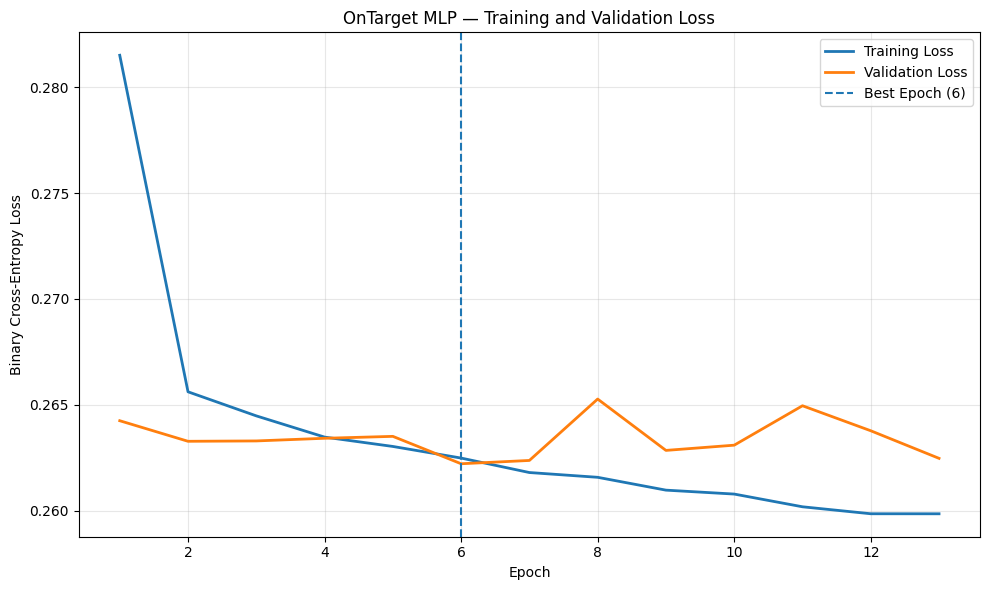

In [26]:

# ============================================================
# 7.4 Plot MLP Training and Validation Loss
# ============================================================

# Create a list of completed epoch numbers.
epochs = range(1, len(train_losses) + 1)

# Create a figure for the learning curves.
plt.figure(figsize=(10, 6))

# Plot the average training loss after each epoch.
plt.plot(
    epochs,
    train_losses,
    label="Training Loss",
    linewidth=2
)

# Plot the average validation loss after each epoch.
plt.plot(
    epochs,
    val_losses,
    label="Validation Loss",
    linewidth=2
)

# Mark the epoch with the best validation loss.
plt.axvline(
    x=best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

# Add a title and labels.
plt.title("OnTarget MLP — Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")

# Display a legend and grid.
plt.legend()
plt.grid(True, alpha=0.3)

# Adjust spacing so labels are visible.
plt.tight_layout()

# Display the completed graph.
plt.show()



## 7.5 Verify the Best Trained Model

After training, we restore the neural network weights from the epoch with the lowest validation loss.

We then perform a final development check to confirm that:

1. The model produces one prediction for each validation shot.
2. All predicted probabilities are between 0 and 1.
3. No invalid numerical values are produced.
4. The restored model achieves the recorded best validation loss.

We use the sigmoid function to convert output logits into predicted goal probabilities.

The held-out testing dataset remains untouched so that the final evaluation can be completed independently.


In [27]:

# ============================================================
# 7.5 Verify the Best Trained MLP
# ============================================================

# Put the model in evaluation mode.
mlp_model.eval()

# Store validation probabilities.
mlp_val_probs_list = []

# Disable gradient calculations.
with torch.no_grad():

    # Process the validation dataset one batch at a time.
    for features, labels in val_loader:

        # Move the features to the selected device.
        features = features.to(device)

        # Get the raw output logits.
        logits = mlp_model(features)

        # Convert logits into goal probabilities.
        probabilities = torch.sigmoid(logits)

        # Move predictions back to CPU for storage.
        probabilities = probabilities.cpu().numpy()

        # Add the batch predictions to our list.
        mlp_val_probs_list.append(probabilities)

# Combine all batches into one NumPy array.
mlp_val_probs = np.concatenate(
    mlp_val_probs_list
).reshape(-1)

# Recalculate validation loss using the restored model.
restored_val_loss = validate_one_epoch(
    mlp_model,
    val_loader,
    criterion
)

# Confirm that the number of predictions is correct.
assert len(mlp_val_probs) == len(y_val)

# Confirm that all predictions contain valid numbers.
assert np.isfinite(mlp_val_probs).all()

# Confirm all probabilities are between 0 and 1.
assert np.all(
    (mlp_val_probs >= 0) &
    (mlp_val_probs <= 1)
)

# Check that the restored loss matches the best saved loss.
assert np.isclose(
    restored_val_loss,
    best_val_loss,
    atol=1e-5
), "Restored model loss does not match the best loss."

# Display verification results.
print("BEST TRAINED MLP VERIFICATION")
print("-" * 55)

print("Best epoch:", best_epoch)
print(f"Recorded best validation loss: {best_val_loss:.4f}")
print(f"Restored model validation loss: {restored_val_loss:.4f}")

print("\nValidation predictions generated:", len(mlp_val_probs))

print("\nFirst five predicted goal probabilities:")
for i, probability in enumerate(mlp_val_probs[:5], start=1):
    print(f"Shot {i}: {probability * 100:.2f}%")

print("\nAll trained-model verification checks passed!")


BEST TRAINED MLP VERIFICATION
-------------------------------------------------------
Best epoch: 6
Recorded best validation loss: 0.2622
Restored model validation loss: 0.2622

Validation predictions generated: 15850

First five predicted goal probabilities:
Shot 1: 90.25%
Shot 2: 5.04%
Shot 3: 3.81%
Shot 4: 10.37%
Shot 5: 2.18%

All trained-model verification checks passed!
